💡 **Environment:** `clamp-analyses` (R kernel)

# Figure 4: drug-disease prediction

Exported at **180 × 78 mm** with all text at least **5 pt** (Nature Methods maximum).

Drug-disease prediction, ARCHS4 and GTEx CLAMPfull and CLAMPbase consensus models and the gene-based
approach (`comparison_methods` in `workflow/config/archs4.yaml`; scores averaged over the top-k thresholds).

- **a**: disease-bootstrap probability that the row method outranks the column method.
- **b**: per-tissue AUROC.

In [1]:
source(here::here("scripts/panels/main_figure.R"))
set.seed(1)
dirs <- main_figure_dirs("fig4")
source_dir <- dirs$source
FIG_W <- 180
FIG_H <- 78

fmt_sci <- function(p) {
  if (p >= .001) return(sprintf("%.3f", p))
  e <- floor(log10(p))
  sup <- c("⁰", "¹", "²", "³", "⁴", "⁵", "⁶", "⁷", "⁸", "⁹")
  paste0(sprintf("%.1f", p / 10^e), "×10⁻", paste0(sup[as.integer(strsplit(as.character(abs(e)), "")[[1]]) + 1], collapse = ""))
}

## Drug-disease prediction

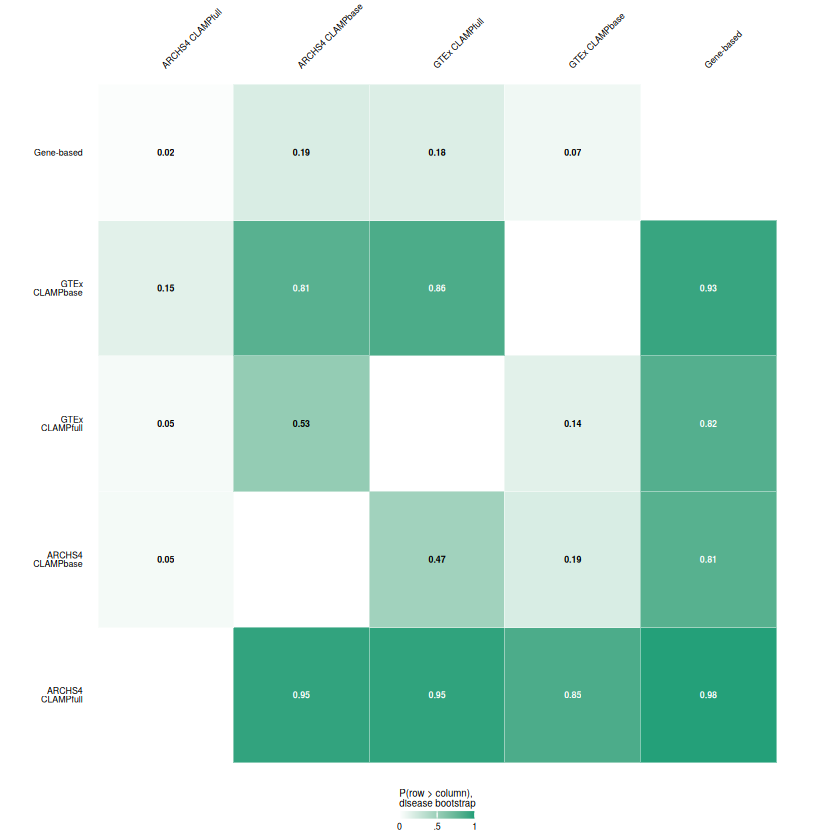

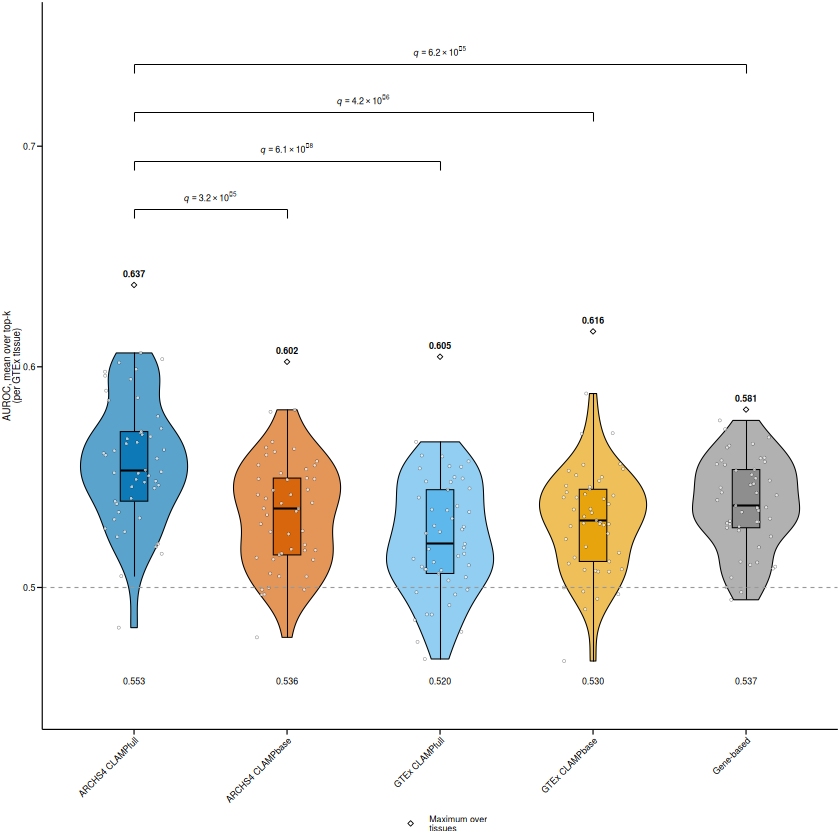

In [2]:
dd_dir <- file.path(DATA_DIR, "02_drug_diseases_canonical", "method_comparison", "data")
dd_order <- names(DRUG_DISEASE_METHOD_COLORS)
dd_colors <- DRUG_DISEASE_METHOD_COLORS
dominance <- fread(file.path(dd_dir, "ordering_stability.csv"))
tissue <- fread(file.path(dd_dir, "per_tissue_metrics.csv"))
agg_ref <- fread(file.path(dd_dir, "max_aggregate_reference.csv"))
tests <- fread(file.path(dd_dir, "paired_tissue_tests.csv"))
stopifnot(uniqueN(tissue$tissue) == 49, setequal(tissue$method, dd_order))
for (nm in c("ordering_stability", "per_tissue_metrics", "max_aggregate_reference", "max_aggregate_ci", "paired_tissue_tests"))
  fwrite(fread(file.path(dd_dir, paste0(nm, ".csv"))), file.path(source_dir, paste0(nm, ".csv")))

dom <- dominance[row_m != col_m]
dom[, `:=`(row_m = factor(row_m, levels = dd_order), col_m = factor(col_m, levels = dd_order))]
plot_a <- ggplot(dom, aes(col_m, row_m, fill = value)) +
  geom_tile(colour = "white") +
  geom_text(aes(label = sprintf("%.2f", value), colour = value >= 0.7), size = 5 / .pt, fontface = "bold",
            show.legend = FALSE) +
  scale_fill_gradient(low = "white", high = "#1B9E77", limits = c(0, 1), name = "P(row > column),\ndisease bootstrap",
                      breaks = c(0, .5, 1), labels = c("0", ".5", "1"),
                      guide = guide_colourbar(direction = "horizontal", title.position = "top",
                                              barwidth = unit(16, "mm"), barheight = unit(1.6, "mm"))) +
  scale_colour_manual(values = c("TRUE" = "white", "FALSE" = "black")) +
  scale_x_discrete(position = "top") +
  scale_y_discrete(labels = function(x) sub(" ", "\n", x)) +
  coord_fixed() +
  labs(x = NULL, y = NULL) +
  theme_nm() +
  theme(axis.line = element_blank(), axis.ticks = element_blank(),
        axis.text.x = element_text(angle = 45, hjust = 0, vjust = 0),
        axis.text.y = element_text(hjust = 1, lineheight = 0.85),
        plot.margin = margin(1, 4, 1, 1, "mm"),
        legend.position = "bottom", legend.justification = "center")

tissue[, method := factor(method, levels = dd_order)]
agg_ref[, method := factor(method, levels = dd_order)]
top_y <- max(tissue$auroc, agg_ref$auroc)
tests_ord <- tests[group1 == dd_order[1] | group2 == dd_order[1]]
tests_ord[, `:=`(xstart = match(group1, dd_order), xend = match(group2, dd_order))]
tests_ord <- tests_ord[order(xend - xstart)]
fmt_q <- function(q) {
  if (q >= 0.001) return(sprintf("italic(q) == %.3f", q))
  parts <- strsplit(formatC(q, format = "e", digits = 1), "e")[[1]]
  sprintf("italic(q) == %s%%*%%10^{%d}", trimws(parts[1]), as.integer(parts[2]))
}
plot_b <- ggplot(tissue, aes(method, auroc, fill = method)) +
  geom_violin(width = 0.7, trim = TRUE, scale = "width", colour = "black", linewidth = 0.22, alpha = 0.65, show.legend = FALSE) +
  geom_boxplot(width = 0.18, outlier.shape = NA, colour = "black", linewidth = 0.22, alpha = 0.85, show.legend = FALSE) +
  geom_jitter(width = 0.2, height = 0, size = 0.5, shape = 21, fill = "white", colour = "#333333", stroke = 0.15, alpha = 0.65) +
  geom_point(data = agg_ref, aes(method, auroc, shape = "Maximum over\ntissues"), size = 1.05, fill = "white",
             colour = "black", stroke = 0.28, inherit.aes = FALSE) +
  geom_text(data = agg_ref, aes(method, auroc, label = sprintf("%.3f", auroc)), vjust = -1.1, size = 5 / .pt, fontface = "bold") +
  geom_text(data = tissue[, .(med = median(auroc)), by = method], aes(method, min(tissue$auroc) - 0.009, label = sprintf("%.3f", med)),
            size = 5 / .pt, inherit.aes = FALSE) +
  scale_fill_manual(values = dd_colors) +
  scale_shape_manual(values = c("Maximum over\ntissues" = 23), name = NULL) +
  geom_hline(yintercept = 0.5, linetype = "dashed", colour = "grey60", linewidth = 0.25) +
  labs(x = NULL, y = "AUROC, mean over top-k\n(per GTEx tissue)") +
  coord_cartesian(ylim = c(min(tissue$auroc) - 0.016, top_y + 0.012 + 0.022 * (nrow(tests_ord) + 0.6))) +
  theme_nm() +
  theme(legend.position = "bottom", legend.margin = margin(0, 0, 0, 0),
        axis.text.x = element_text(angle = 45, hjust = 1, vjust = 1))
for (i in seq_len(nrow(tests_ord))) {
  y <- top_y + 0.012 + 0.022 * i
  plot_b <- plot_b +
    annotate("segment", x = tests_ord$xstart[i], xend = tests_ord$xstart[i], y = y - 0.004, yend = y, linewidth = 0.22) +
    annotate("segment", x = tests_ord$xstart[i], xend = tests_ord$xend[i], y = y, yend = y, linewidth = 0.22) +
    annotate("segment", x = tests_ord$xend[i], xend = tests_ord$xend[i], y = y - 0.004, yend = y, linewidth = 0.22) +
    annotate("text", x = (tests_ord$xstart[i] + tests_ord$xend[i]) / 2, y = y + 0.003,
             label = fmt_q(tests_ord$q_value_bh[i]), parse = TRUE, size = 5 / .pt, vjust = 0)
}
print(plot_a)
print(plot_b)

## Assemble and save

fig4: 180 x 78 mm -> /home/msubirana/Documents/pivlab/clamp-analyses-drop-projection/output/99_panels/fig4


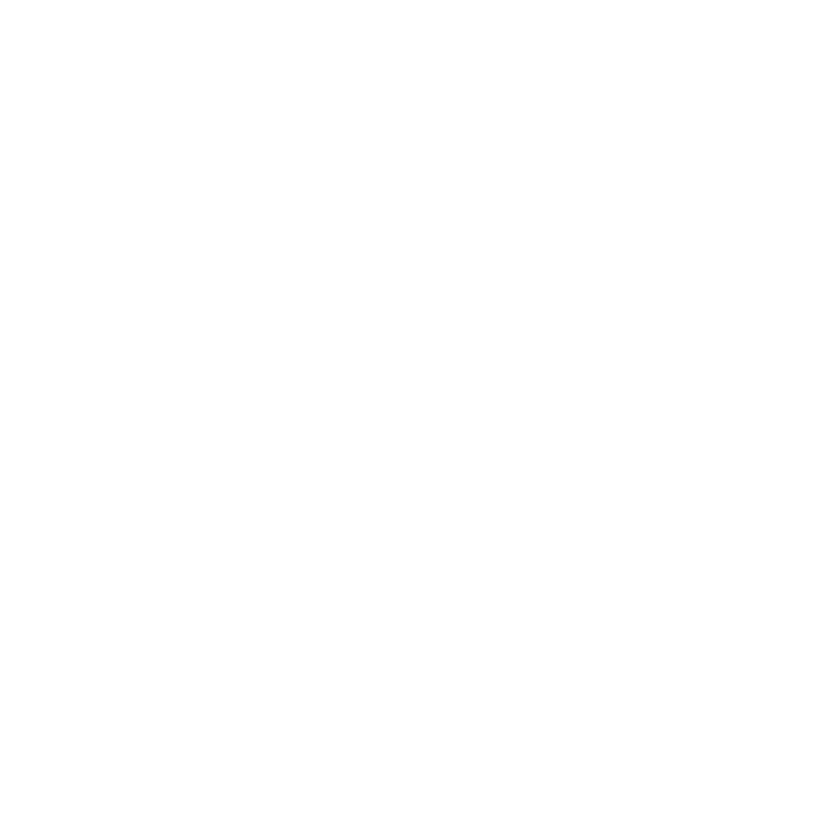

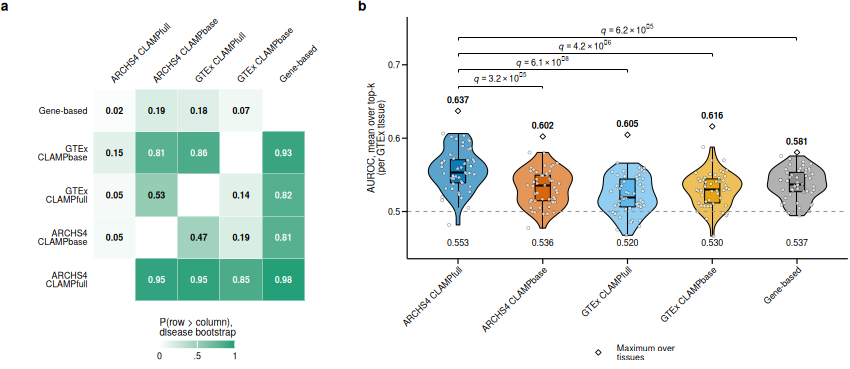

In [3]:
fig4 <- plot_grid(add_tag(plot_a, "a", top = 0.96), add_tag(plot_b, "b", top = 0.96), nrow = 1, rel_widths = c(0.42, 0.58))
writeLines(c(sprintf("Figure 4: %d x %d mm; minimum text 5 pt.", FIG_W, FIG_H),
             "a-b: 02_drug_diseases_canonical/method_comparison/data (mean over 5/10/25/50 modules or 50/100/250/500 genes, max over 49 tissues; disease-clustered bootstrap; brackets: per-tissue two-sided paired Wilcoxon, BH q)."),
           file.path(source_dir, "README.txt"))
save_main_figure(fig4, "fig4", FIG_W, FIG_H)
options(repr.plot.width = FIG_W / 25.4, repr.plot.height = FIG_H / 25.4)
print(fig4)